# Prueba Intertrimestral

**Nombre:**  
**Apellidos:**  

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [145]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [146]:
BASE_FEE = {"classic": 1.00, "electric": 1.50}   # € por viaje
PER_MINUTE = {"classic": 0.05, "electric": 0.08}  # € por minuto
MEMBER_DISCOUNT = 0.20                            # 20 % para abonados


def rental_fee(duration_min, bike_type, is_member):

    if bike_type not in BASE_FEE:
        raise ValueError(f"bike_type debe ser 'classic' o 'electric', no {bike_type!r}")
    if duration_min < 0:
        raise ValueError("duration_min no puede ser negativa")

    fee = BASE_FEE[bike_type] + PER_MINUTE[bike_type] * duration_min
    if is_member:
        fee *= 1 - MEMBER_DISCOUNT
    return round(fee, 2)

In [147]:
# Comprobaciones
print(f"{rental_fee(20, 'classic', False):.2f}")   # 1.00 + 20*0.05        = 2.00 (ejemplo del enunciado)
print(f"{rental_fee(20, 'electric', False):.2f}")  # 1.50 + 20*0.08        = 3.10
print(f"{rental_fee(20, 'electric', True):.2f}")   # 3.10 * 0.80           = 2.48
try:
    rental_fee(10, "scooter", False)
except ValueError as error:
    print("ValueError:", error)

2.00
3.10
2.48
ValueError: bike_type debe ser 'classic' o 'electric', no 'scooter'


b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [148]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    elif total_rentals >= threshold / 2:
        return "Media"
    return "Baja"

c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [149]:
rng = np.random.default_rng(42)
N_VIAJES = 12
THRESHOLD = 40

tripsDemo = pd.DataFrame({
    "duration_min": rng.uniform(3, 45, N_VIAJES).round(1),
    "bike_type": rng.choice(["classic", "electric"], N_VIAJES),
    "is_member": rng.choice([True, False], N_VIAJES),
    "total_rentals": rng.integers(0, 80, N_VIAJES),
})


# aplicar funciones creadas antes
tripsDemo["fee"] = tripsDemo.apply(
    lambda row: rental_fee(row["duration_min"], row["bike_type"], row["is_member"]),
    axis=1,
)
tripsDemo["demand"] = tripsDemo["total_rentals"].apply(demand_label, threshold=THRESHOLD)

# orden de columnas del enunciado
tripsDemo = tripsDemo[["duration_min", "bike_type", "is_member", "fee", "total_rentals", "demand"]]

display(tripsDemo)


,duration_min,bike_type,is_member,fee,total_rentals,demand
0,35.5,electric,False,4.34,54,Alta
1,21.4,electric,False,3.21,62,Alta
2,39.1,classic,True,2.36,60,Alta
3,32.3,electric,False,4.08,15,Baja
4,7.0,electric,True,1.65,29,Media
5,44.0,classic,False,3.20,37,Media
6,35.0,classic,False,2.75,39,Media
7,36.0,classic,True,2.24,3,Baja
8,8.4,classic,True,1.14,43,Alta
9,21.9,electric,False,3.25,12,Baja


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [150]:
class MicromobilityTools:

    BASE_FEE = {"classic": 1.00, "electric": 1.50}
    PER_MINUTE = {"classic": 0.05, "electric": 0.08}
    MEMBER_DISCOUNT = 0.20

    def __init__(self, threshold=40):
        self.threshold = threshold

    def rental_fee(self, duration_min, bike_type, is_member):
        """Misma funcion que antes"""
        if bike_type not in self.BASE_FEE:
            raise ValueError(f"bike_type debe ser 'classic' o 'electric', no {bike_type!r}")
        if duration_min < 0:
            raise ValueError("duration_min no puede ser negativa")
        fee = self.BASE_FEE[bike_type] + self.PER_MINUTE[bike_type] * duration_min
        if is_member:
            fee *= 1 - self.MEMBER_DISCOUNT
        return round(fee, 2)

    def demand_label(self, total_rentals):
        """Misma funcion que antes"""
        if total_rentals >= self.threshold:
            return "Alta"
        elif total_rentals >= self.threshold / 2:
            return "Media"
        return "Baja"

    def process(self, durations, bike_types, is_members, total_rentals=None):
        """
        Devuelve un DataFrame con la tarifa de cada viaje y, si se pasatotal_rentals, también la etiqueta de demanda.
        """
        if not len(durations) == len(bike_types) == len(is_members):
            raise ValueError("durations, bike_types e is_members deben tener la misma longitud")

        result = pd.DataFrame({
            "duration_min": durations,
            "bike_type": bike_types,
            "is_member": is_members,
        })
        result["fee"] = [
            self.rental_fee(d, b, m) for d, b, m in zip(durations, bike_types, is_members)
        ]

        if total_rentals is not None:
            if len(total_rentals) != len(durations):
                raise ValueError("total_rentals debe tener la misma longitud que el resto")
            result["total_rentals"] = total_rentals
            result["demand"] = [self.demand_label(n) for n in total_rentals]

        return result

In [ ]:
#pruebas
tools = MicromobilityTools(threshold=THRESHOLD)

#solo fees
display(tools.process([10, 25, 40], ["classic", "electric", "classic"], [False, True, True]))

# fees + demanda, reutilizando los datos de tripsDemo
ejemploClase = tools.process(
    tripsDemo["duration_min"].tolist(),
    tripsDemo["bike_type"].tolist(),
    tripsDemo["is_member"].tolist(),
    total_rentals=tripsDemo["total_rentals"].tolist(),
)
ejemploClase.head()

,duration_min,bike_type,is_member,fee
0,10,classic,False,1.5
1,25,electric,True,2.8
2,40,classic,True,2.4


,duration_min,bike_type,is_member,fee,total_rentals,demand
0,35.5,electric,False,4.34,54,Alta
1,21.4,electric,False,3.21,62,Alta
2,39.1,classic,True,2.36,60,Alta
3,32.3,electric,False,4.08,15,Baja
4,7.0,electric,True,1.65,29,Media


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [ ]:
# convierte datetim en fecha en vez de dejarlo como texto
mobilityData = pd.read_csv("city_micromobility_hourly.csv", parse_dates=["datetime"])

display(mobilityData.head())

n_rows, n_cols = mobilityData.shape
print(f"mobilityData tiene {n_rows} filas y {n_cols} columnas")

,datetime,year,month,day,hour,weekday,season,is_holiday,is_weekend,is_workingday,...,wind_kmh,precip_mm,casual_users,member_users,total_rentals,avg_trip_min,avg_distance_km,electric_share,revenue_eur,high_demand
0,2025-01-01 00:00:00,2025,1,1,0,2,Winter,1,0,0,...,9.7,0.0,2,8,10,23.3,4.94,0.391,10.83,0
1,2025-01-01 01:00:00,2025,1,1,1,2,Winter,1,0,0,...,2.8,0.0,1,5,6,17.3,3.92,0.327,5.35,0
2,2025-01-01 02:00:00,2025,1,1,2,2,Winter,1,0,0,...,9.0,0.0,1,4,5,17.3,4.24,0.405,4.77,0
3,2025-01-01 03:00:00,2025,1,1,3,2,Winter,1,0,0,...,5.4,0.0,2,10,12,17.3,3.98,0.408,10.88,0
4,2025-01-01 04:00:00,2025,1,1,4,2,Winter,1,0,0,...,2.4,0.0,1,4,5,21.6,5.90,0.336,5.16,0


mobilityData tiene 17520 filas y 23 columnas


b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [153]:
def describeData(dataFrame):
    """
    Resume cada columna de un DataFrame.

    Args:
        dataFrame: datos a analizar.

    Returns:
        pd.DataFrame: una fila por columna con el tipo de dato,
        el número de nulos y el porcentaje de nulos.
    """
    n_nulls = dataFrame.isna().sum()
    return pd.DataFrame({
        "Dtype": dataFrame.dtypes,
        "Nulos": n_nulls,
        "% Nulos": (n_nulls / len(dataFrame) * 100).round(2),
    })
describeData(mobilityData)

,Dtype,Nulos,% Nulos
datetime,datetime64[ns],0,0.00
year,int64,0,0.00
month,int64,0,0.00
day,int64,0,0.00
hour,int64,0,0.00
weekday,int64,0,0.00
season,object,0,0.00
is_holiday,int64,0,0.00
is_weekend,int64,0,0.00
is_workingday,int64,0,0.00


c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [154]:
resumen = describeData(mobilityData)
resumen[resumen["Nulos"] > 0].sort_values("% Nulos", ascending=False)

,Dtype,Nulos,% Nulos
avg_trip_min,float64,255,1.46
humidity,float64,224,1.28
electric_share,float64,182,1.04
wind_kmh,float64,142,0.81


 Solo 4 columnas numéricas tienen nuls, y en todas el porcentaje es pequeño: avg_trip_min (≈1,5 %), humidity (≈1,3 %), electric_share (≈1,0 %) y wind_kmh (≈0,8 %). El resto, incluido el objetivo total_rentals, está completo.

Antes de modelar, con porcentajes tan bajos, eliminaria esas filas ya que apeas reduce la muestra y es la opción más simple

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


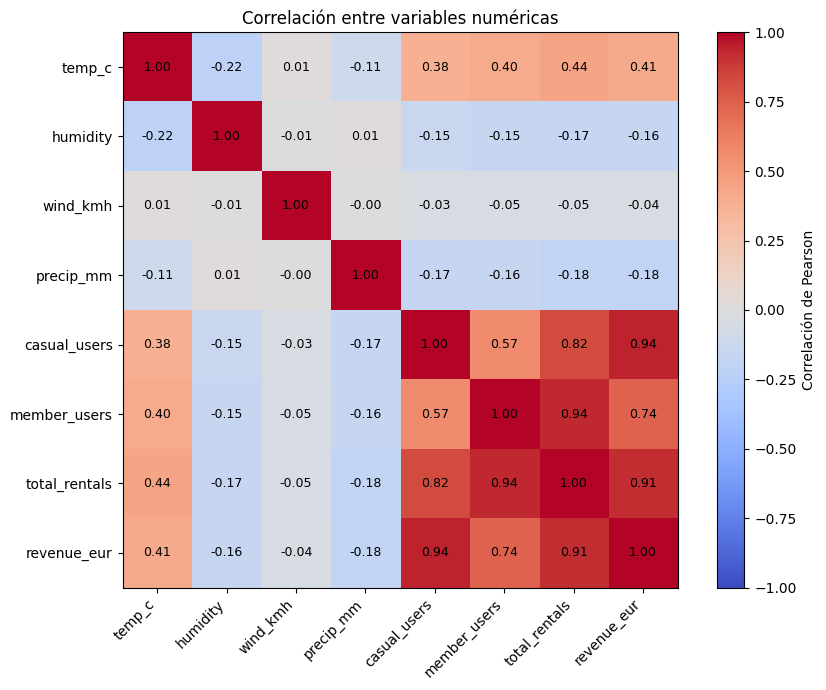

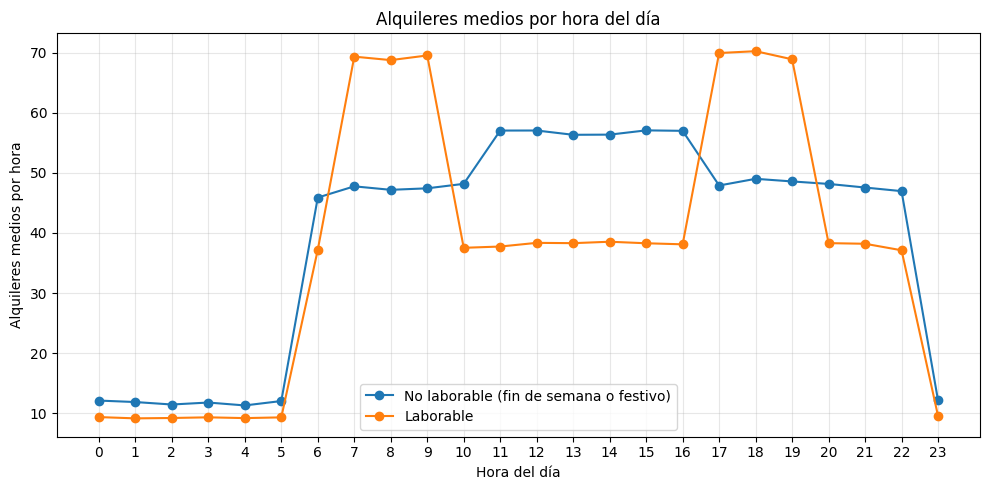

In [164]:
# --- 1) Matriz de correlación ---------------------------------------------------
corr_vars = ["temp_c", "humidity", "wind_kmh", "precip_mm",
             "casual_users", "member_users", "total_rentals", "revenue_eur"]
corr = mobilityData[corr_vars].corr() 

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_vars)), corr_vars, rotation=45, ha="right")
ax.set_yticks(range(len(corr_vars)), corr_vars)
for i in range(len(corr_vars)):
    for j in range(len(corr_vars)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

# --- 2) Demanda media por hora: laborable vs no laborable --------------------------

hourly = (
    mobilityData
    .groupby(["hour", "is_workingday"])["total_rentals"]
    .mean()
    .unstack()
    .rename(columns={0: "No laborable (fin de semana o festivo)", 1: "Laborable"})
)

fig, ax = plt.subplots(figsize=(10, 5))
hourly.plot(ax=ax, marker="o")
ax.set_title("Alquileres medios por hora del día")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Alquileres medios por hora")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend(title="")
plt.tight_layout()
plt.show()



Con estos graficos señalar 3 importantes hayazgos:
- La hora tiene un impacto muy fuerte en los alquileres medios
- CUando el dia es No laborable los picos de demanda se suavizan mucho, dejando una demanda mucho mas uniforme durante las horas del dia
- La mayoria de las variables numericas tien una correlacion bastante baja, salvo la temperatura, que si que tiene un efecto positivo sobre la demanda

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [156]:
targetVar = "total_rentals"
predictors = ["hour", "temp_c", "humidity", "precip_mm", "is_workingday"]

model_data = mobilityData[predictors + [targetVar]].dropna()
X = model_data[predictors]
y = model_data[targetVar]

print(f"Filas eliminadas por nulos: {len(mobilityData) - len(model_data)}")

Filas eliminadas por nulos: 224


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [157]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [158]:
lm = LinearRegression()
lm.fit(x_train, y_train)

y_pred_lm = lm.predict(x_test)  
r2_lm = r2_score(y_test, y_pred_lm)
mse_lm = mean_squared_error(y_test, y_pred_lm)

print(f"Regresión lineal -> R²: {r2_lm:.3f} | MSE: {mse_lm:.1f} | RMSE: {np.sqrt(mse_lm):.1f} alquileres")
print()
print("Coeficientes:")
print(pd.Series(lm.coef_, index=predictors).round(2))

Regresión lineal -> R²: 0.320 | MSE: 403.7 | RMSE: 20.1 alquileres

Coeficientes:
hour             1.06
temp_c           0.96
humidity        -0.14
precip_mm       -9.34
is_workingday   -2.30
dtype: float64


La regresión lineal tiene solo un R² ≈ 0,32 y se equivoca de media en unos **20 alquileres** (RMSE). Es una prediccion pobre. El motivo está en el gráfico por horas: la demanda **no crece en línea recta con la hora**, sino que tiene dos picos, y además la forma de la curva cambia según el día sea laborable o no. Un modelo lineal solo puede ajustar relaciones lineales con la hora y no capta esos picos.

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [159]:
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(x_train, y_train)

y_pred_rf = rf.predict(x_test)
r2_rf = r2_score(y_test, y_pred_rf)        
mse_rf = mean_squared_error(y_test, y_pred_rf)

comparison = pd.DataFrame({
    "R²": [r2_lm, r2_rf],
    "MSE": [mse_lm, mse_rf],
    "RMSE": [np.sqrt(mse_lm), np.sqrt(mse_rf)],
}, index=["Regresión lineal", "Random Forest"]).round(3)
display(comparison)


,R²,MSE,RMSE
Regresión lineal,0.320,403.658,20.091
Random Forest,0.883,69.475,8.335


 El random forest funciona claramente mejor: tiene un R² ≈ **0,88** frente a 0,32 de la regresion lineal, y el MSE baja de unos 404 a unos **69**, es decir, el error típico pasa de ~20 a **~8**. Eso es asi ya que el árbol divide los datos por umbrales ("hora entre 7 y 9 *y* laborable"), así que capta los **picos horarios** (que no sigue una relacion lineal) y la **interacción hora × tipo de día** sin que tengamos que programarlas. La regresión lineal tendría que recibir esas formas ya preparadas, por ejemplo con la hora codificada como categoría (one-hot) o con términos de interacción.


## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [160]:
print(mobilityData["high_demand"].value_counts())
print()
class_share = mobilityData["high_demand"].value_counts(normalize=True)
print(class_share.round(3))


high_demand
0    12071
1     5449
Name: count, dtype: int64

high_demand
0    0.689
1    0.311
Name: proportion, dtype: float64


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [161]:
class_numeric = ["temp_c", "humidity", "wind_kmh", "precip_mm", "is_workingday", "is_holiday"]
class_features = ["hour"] + class_numeric


class_data = mobilityData[class_features + ["high_demand"]].dropna()
X_class = class_data[class_features]
y_class = class_data["high_demand"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class, y_class,
    test_size=0.3,
    random_state=42,
    stratify=y_class,  
)

logit_model = Pipeline([
    ("prep", ColumnTransformer([
        ("hour", OneHotEncoder(handle_unknown="ignore"), ["hour"]),
        ("num", StandardScaler(), class_numeric),
    ])),
    ("logit", LogisticRegression(max_iter=1000)),
])
logit_model.fit(X_train_c, y_train_c)



print(f"Entrenamiento: {X_train_c.shape} | Prueba: {X_test_c.shape}")

Entrenamiento: (12011, 7) | Prueba: (5148, 7)


c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


Accuracy:       0.853



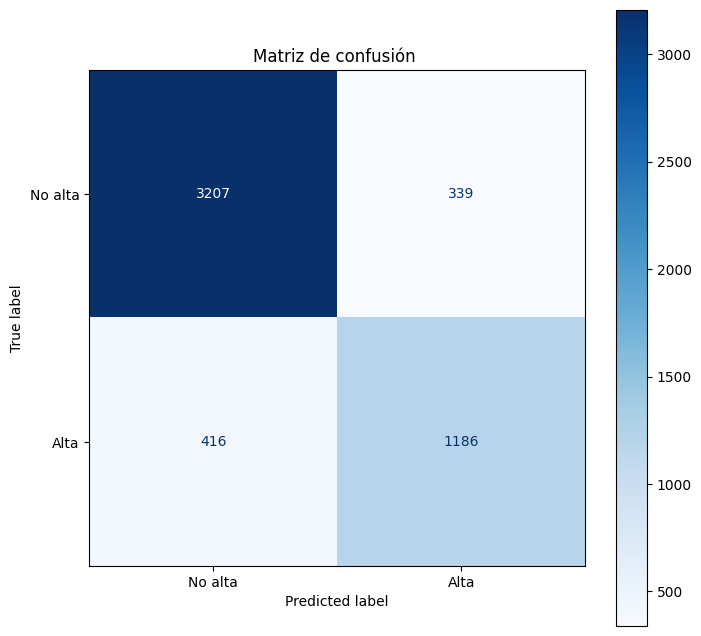

In [162]:
y_pred_c = logit_model.predict(X_test_c)


print(f"Accuracy:       {accuracy_score(y_test_c, y_pred_c):.3f}")
print()
disp = ConfusionMatrixDisplay(
        confusion_matrix(y_test_c, y_pred_c), display_labels=["No alta", "Alta"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title(f"Matriz de confusión ")
plt.show()


d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


Coeficientes de las variables:
precip_mm       -1.25
temp_c           1.15
is_workingday   -0.42
humidity        -0.38
wind_kmh        -0.24
is_holiday      -0.03
dtype: float64


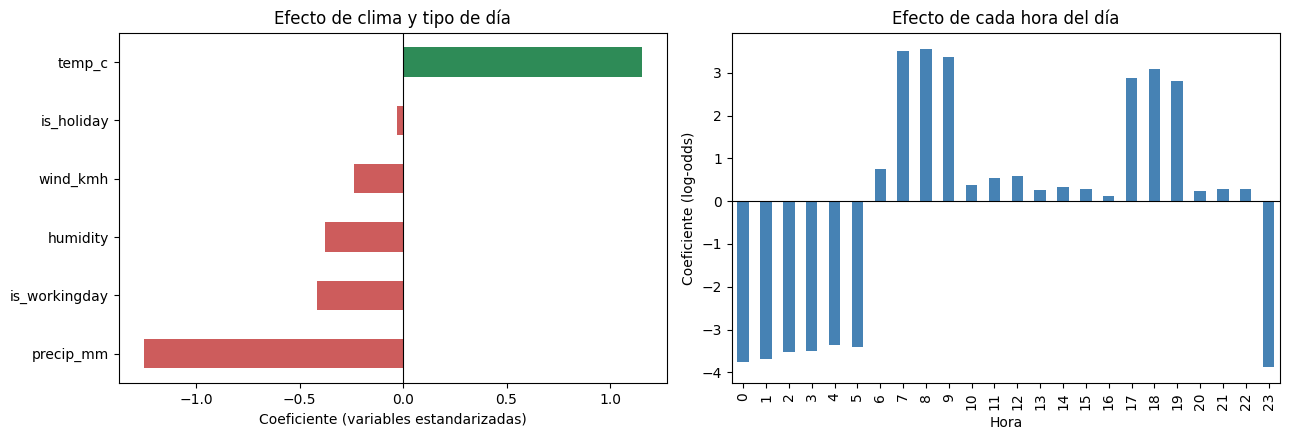

In [163]:
logit = logit_model.named_steps["logit"]
feature_names = logit_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(logit.coef_[0], index=feature_names)


numeric_coefs = coefs[coefs.index.str.startswith("num__")].rename(lambda s: s.replace("num__", ""))
hour_coefs = coefs[coefs.index.str.startswith("hour__")]
hour_coefs.index = [int(s.replace("hour__hour_", "")) for s in hour_coefs.index]

print("Coeficientes de las variables:")
print(numeric_coefs.sort_values(key=abs, ascending=False).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

numeric_coefs.sort_values().plot.barh(
    ax=axes[0], color=["indianred" if c < 0 else "seagreen" for c in numeric_coefs.sort_values()]
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Efecto de clima y tipo de día")
axes[0].set_xlabel("Coeficiente (variables estandarizadas)")

hour_coefs.sort_index().plot.bar(ax=axes[1], color="steelblue")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Efecto de cada hora del día")
axes[1].set_xlabel("Hora")
axes[1].set_ylabel("Coeficiente (log-odds)")

plt.tight_layout()
plt.show()

Podemos ver que las variables con mas impacto son:

- **La hora es el factor dominante.** Los coeficientes por hora son muy negativos de madrugada (0-5 h y 23 h), muy positivos en las horas punta (7-9 h y 17-19 h) y ligeramente positivos el resto del día. Esto encaja con el gráfico del ejercicio 2: la franja horaria decide casi por sí sola si una hora puede ser de alta demanda
- **Lluvia (−1,25) y temperatura (+1,15)** son, tras la hora, lo que más pesa: la precipitación hunde la demanda y el calor la empuja. La humedad y el viento restan, pero bastante menos

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).




Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



**Qué mueve la demanda.** El factor principal es la **hora del día combinada con el tipo de día**. En laborables la demanda se concentra en las horas punta de transito al trabajo. En fines de semana y festivos se reparte en una meseta de ocio entre las 11 y las 16 h. Por la noche es casi nula. Después viene el **clima**: la temperatura es la variable  más relacionada con la demanda (r = +0,44), y la lluviatambien la reduce con fuerza. Humedad y viento tienen un efecto menor.

**Mejor modelo.** En regresión, el **Random Forest** (R² ≈ 0,88) supera con mucho a la regresión lineal (R² ≈ 0,32), porque capta sin ayuda los picos horarios y la interacción entre hora y tipo de día. En clasificación pasa lo mismo: la regresión logística solo funciona bien cuando la hora se trata como categoría. La lección es que la relación con la hora **no es lineal**, y hay que usar un modelo que lo capte o transformar la variable.

**Mejoras con más tiempo o datos.**
- Validación **temporal** (entrenar con 2025 y probar con 2026) en vez de un split aleatorio.
- Variables de **retardo** (la demanda de la hora anterior o de la misma hora la semana pasada) y la interacción hora × laborable explícita.
- **Datos nuevos**: eventos, calendario escolar, varias ciudades o zonas, precio dinámico y previsiones meteorológicas (no el tiempo observado) para predecir con antelación.